### tanh

In [1]:
using DifferentialEquations, Plots
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)

mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")


τ = 3/4 # doubling time 44min
r = log(2)/τ

0.9241962407465937

In [2]:
function f_exp(du, u, p, t)
    du[1] = r * u[1] * 0.3
end

function affect!(integrator)
    global last_div
    last_div = integrator.u[1]
    integrator.u[1] = integrator.u[1]/2
end

function rate_tanh(u, p, t)
    # (1 + tanh((u[1] - last_div)/0.8)) * 20
    a = 0.5
    l0 = 10.0
    w = 0.8
    lam = 20
    (1 + tanh((u[1] - (a * l0 + (1 - a) * last_div))/w)) * lam
    
end


rate_tanh (generic function with 1 method)

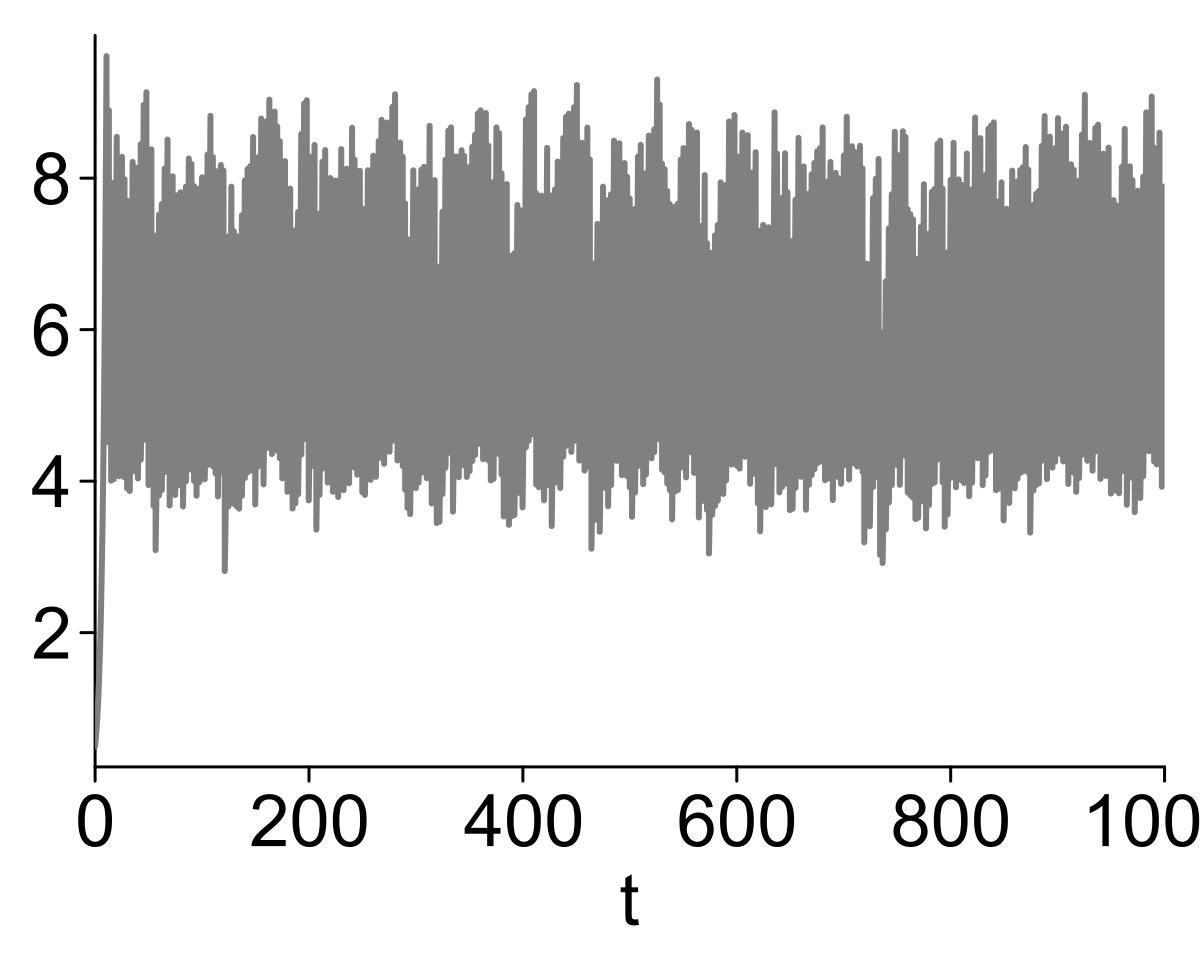

In [3]:
u0 = [0.5]
T = 1000.0
tspan = (0.0, T)
t = 0:0.001:T
global last_div
last_div = 10.0
prob = ODEProblem(f_exp, u0, tspan)

jump = VariableRateJump(rate_tanh, affect!)
jump_prob = JumpProblem(prob, Direct(), jump)
sol = solve(jump_prob, Tsit5())

In [4]:
Lsim = Array(sol')[:,1];
tsim = sol.t;
isdiv_sim, _ = annotate_sim_traj(Lsim, tsim);

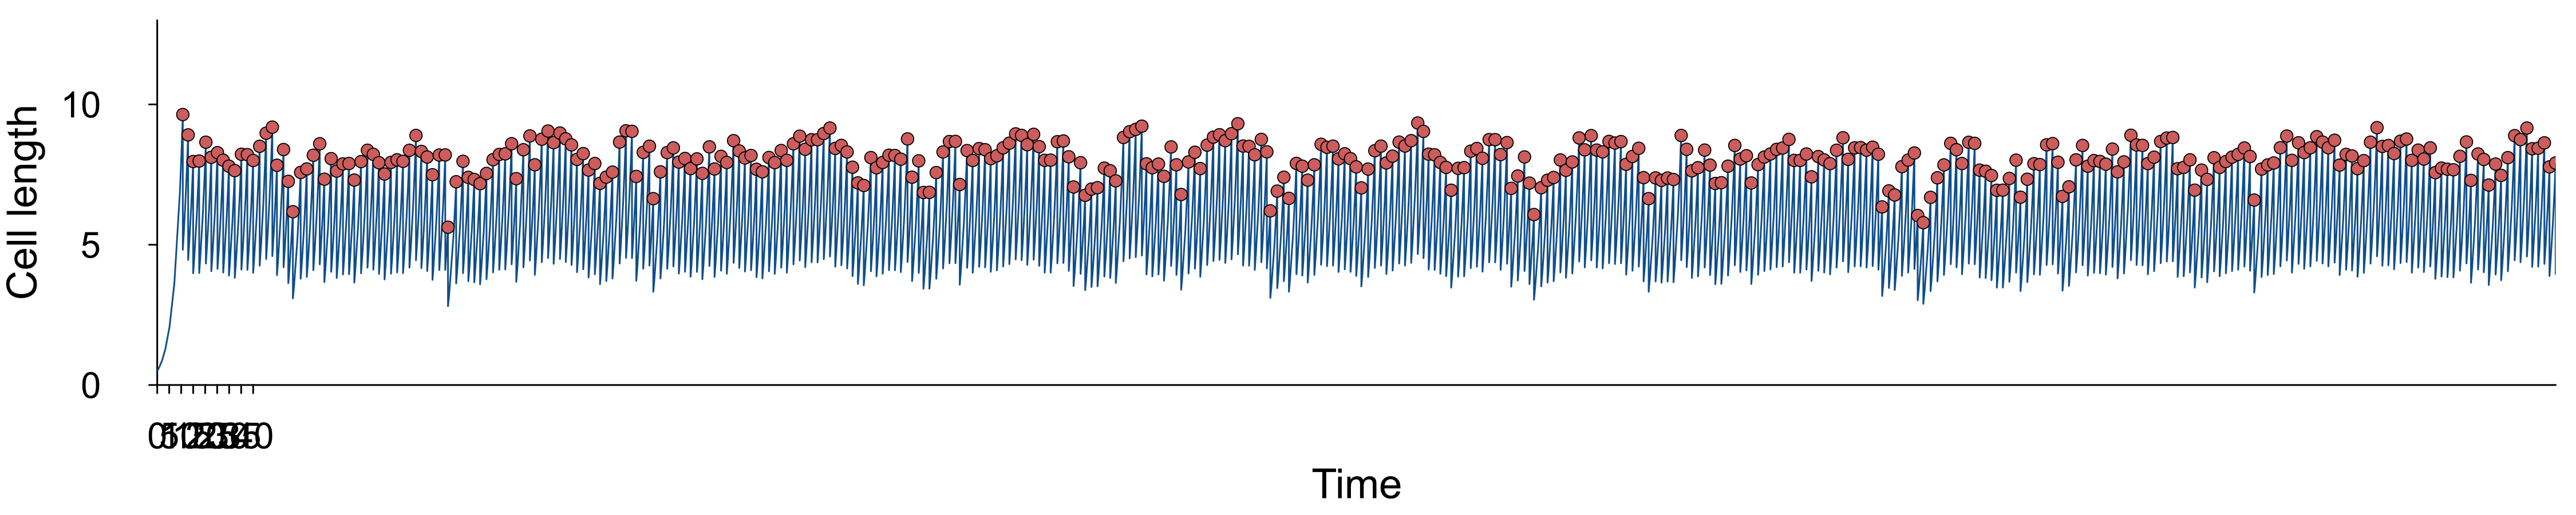

In [12]:
p_traj = plot(; size=(1500,300), xlim=(0,1000), ylim=(0,15), xtick=collect(0:5:40), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time", ylabel="Cell length")
plot!(p_traj, tsim, Lsim, grid=false, legend=false, lw=1, lc=:dodgerblue4, size=(1500,300), ylim=(0, 13), tickfontsize=14, ytick=[0,5,10])
scatter!(tsim[isdiv_sim], Lsim[isdiv_sim])

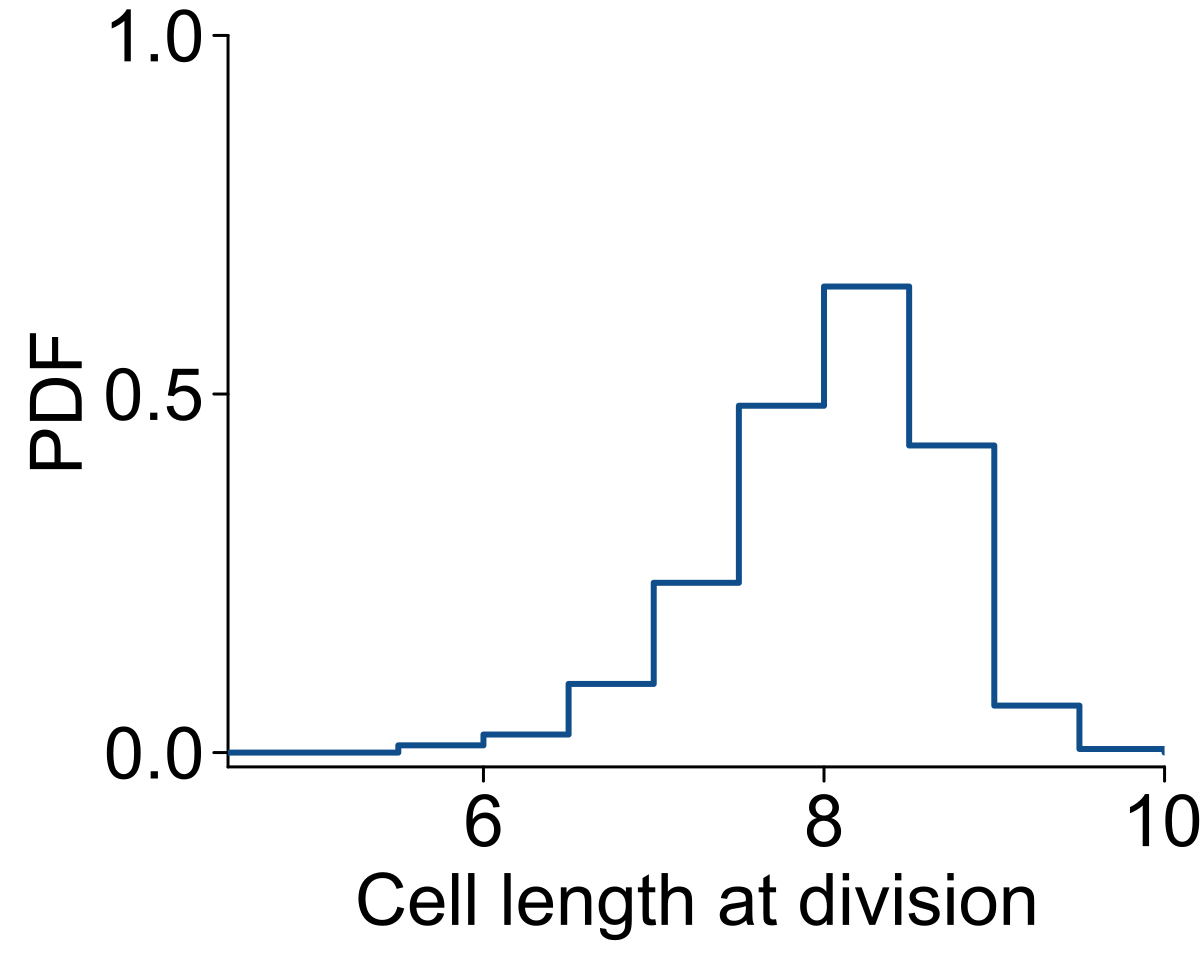

In [5]:
stephist(Lsim[isdiv_sim], normalize=:pdf,
xlim=(4.5,10), xtick=[4,6,8,10],ylim=(-0.02,1),ytick=collect(0:0.5:2), bins=collect(4.5:0.5:10),
         ylabel="PDF", xlabel="Cell length at division", lc=:dodgerblue4, lw=:2)

In [6]:
using StatsBase
hedges = collect(4:0.5:10);
hbins = 0.5*( hedges[1:end-1] + hedges[2:end] )
dhedges = mean( diff(hedges) );
h1_sim = fit(Histogram, Lsim[isdiv_sim], hedges)
h2_sim = fit(Histogram, (Lsim[isdiv_sim][1:end-1], Lsim[isdiv_sim][2:end]), (hedges,hedges));


In [7]:
h1_sim_normalize = h1_sim.weights / sum(h1_sim.weights) / dhedges
h2_sim_normalize = h2_sim.weights / sum(h2_sim.weights) / dhedges^2

svd_h1_sim = svd(h1_sim_normalize * h1_sim_normalize');
svd_h2_sim = svd(h2_sim_normalize);

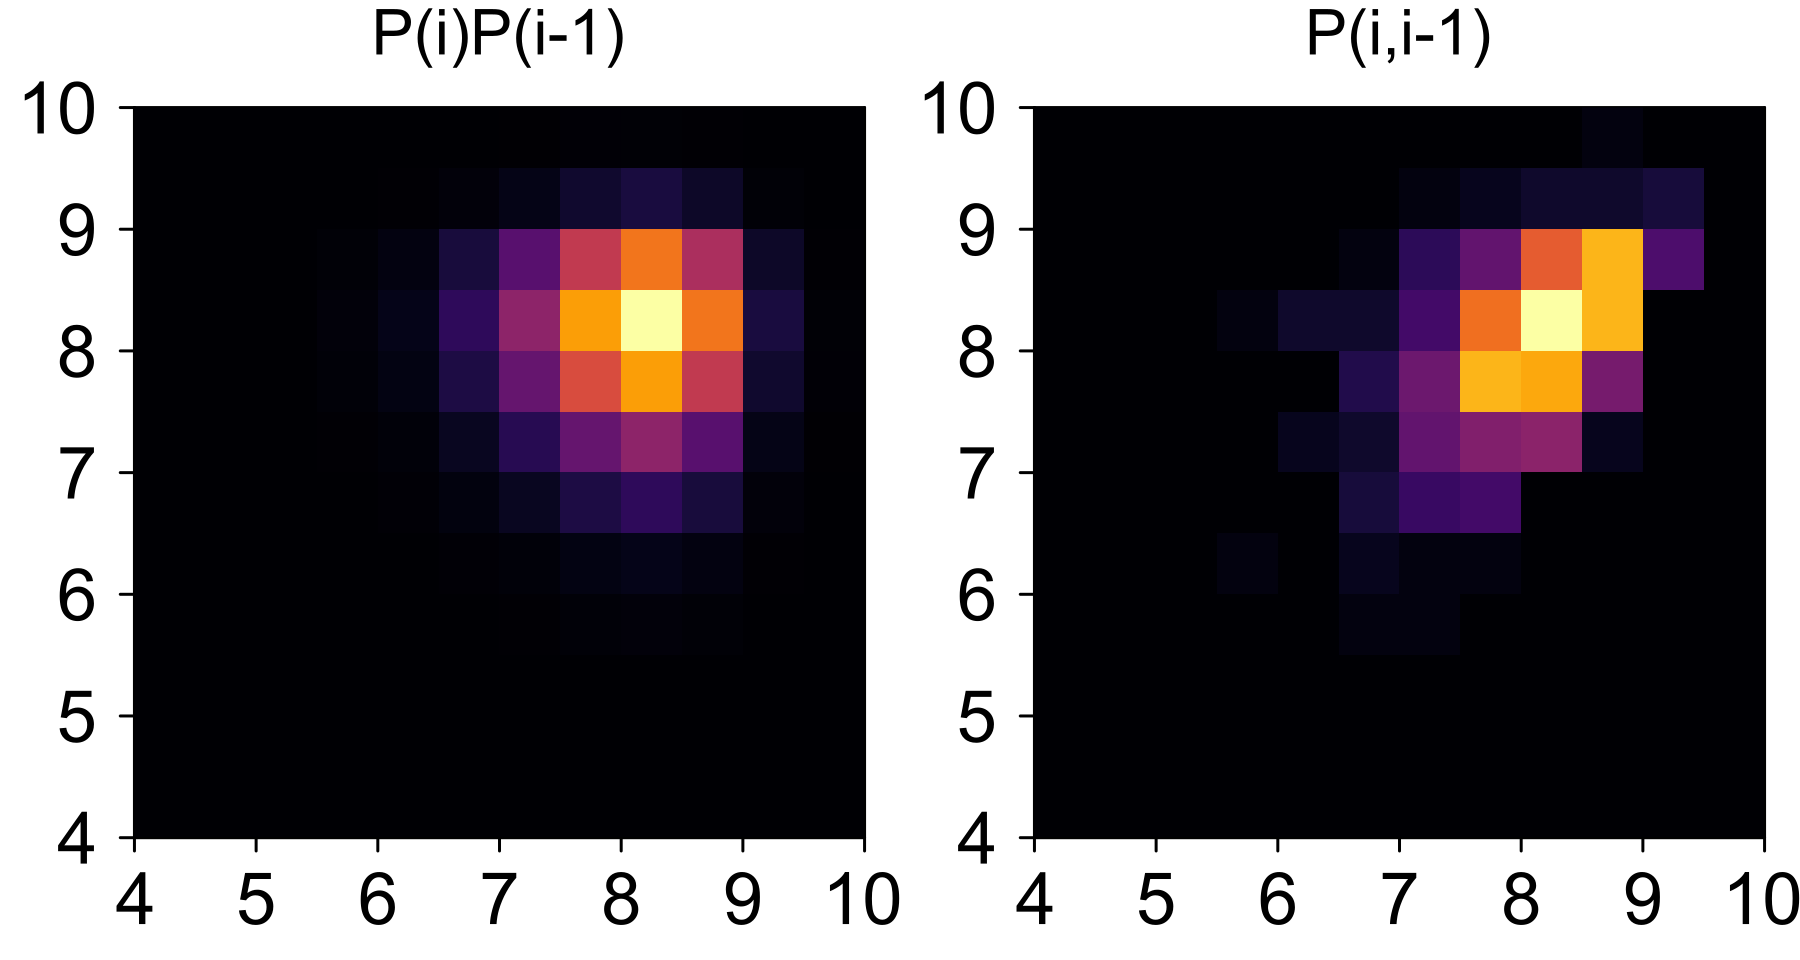

In [13]:
ll=@layout [a b]
p_h1_sim = plot(; aspect_ratio=1, framestyle=:box, xlim=(4,10), ylim=(4,10), xtick=collect(4:10), ytick=collect(4:10), title="P(i)P(i-1)" )
heatmap!( p_h1_sim, hbins, hbins, h1_sim_normalize * h1_sim_normalize', clim=(0,0.4)) 

p_h2_sim = plot(; aspect_ratio=1, framestyle=:box, xlim=(4,10), ylim=(4,10), xtick=collect(4:10), ytick=collect(4:10), title="P(i,i-1)" )
heatmap!( p_h2_sim, hbins, hbins, h2_sim_normalize, clim=(0,0.4)) 

plot(p_h1_sim, p_h2_sim, layout = ll, size=(600,320))

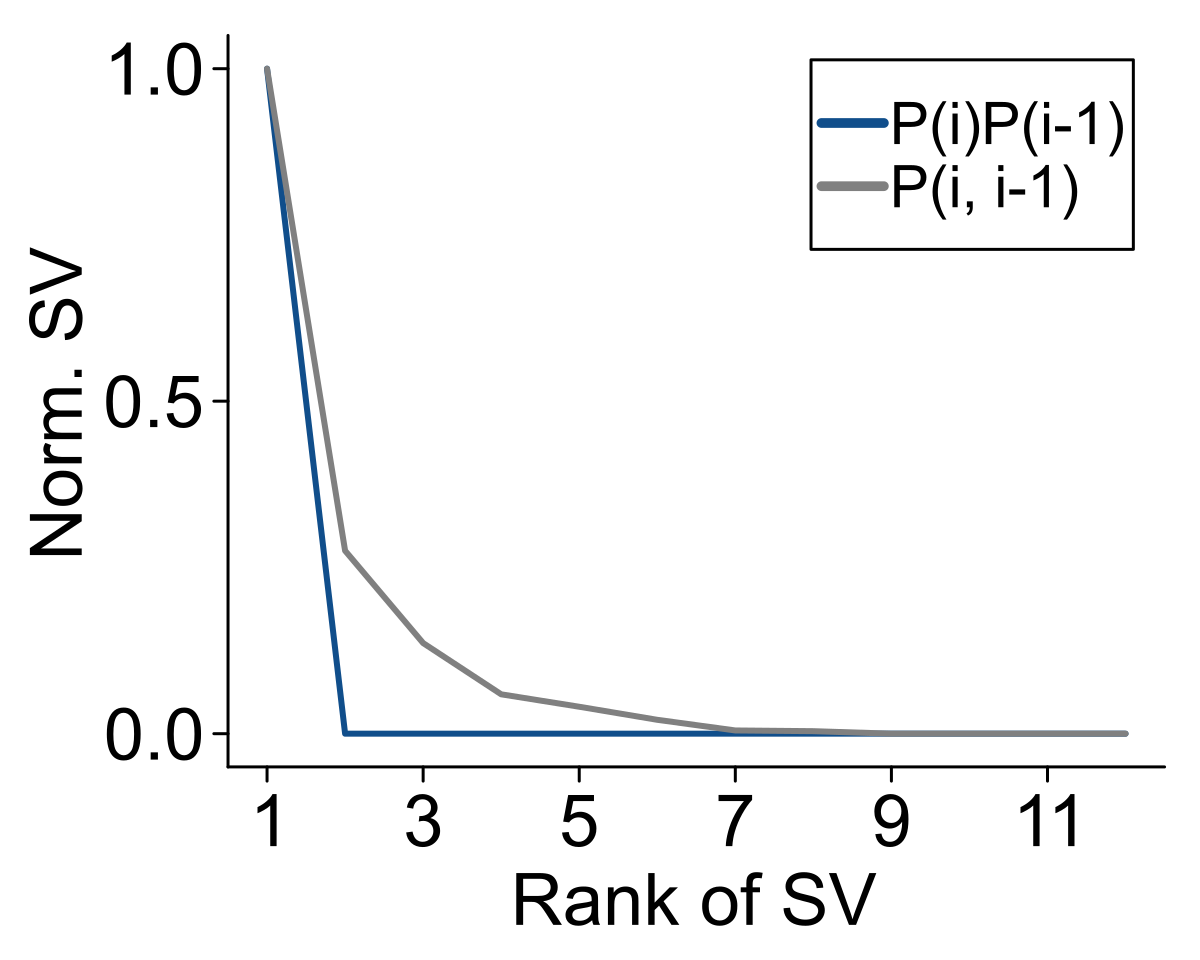

In [14]:
p_S_sim = plot(; xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)
plot!( p_S_sim, svd_h1_sim.S ./ svd_h1_sim.S[1], lc=:dodgerblue4, label="P(i)P(i-1)" )
plot!( p_S_sim, svd_h2_sim.S ./ svd_h2_sim.S[1],  label="P(i, i-1)" )

In [16]:
function plot_histogram!( pp, _hedges::Vector{T}, _y::Vector{T}; plot_args...) where T
    _index_edges = vcat([[i,i] for i in 1:length(_hedges)]...);
    _index_y = vcat([[i,i] for i in 1:length(_y)]...);
    plot!(pp, _hedges[_index_edges[2:end-1]], _y[_index_y]; plot_args...)
    nothing
end

plot_histogram! (generic function with 1 method)

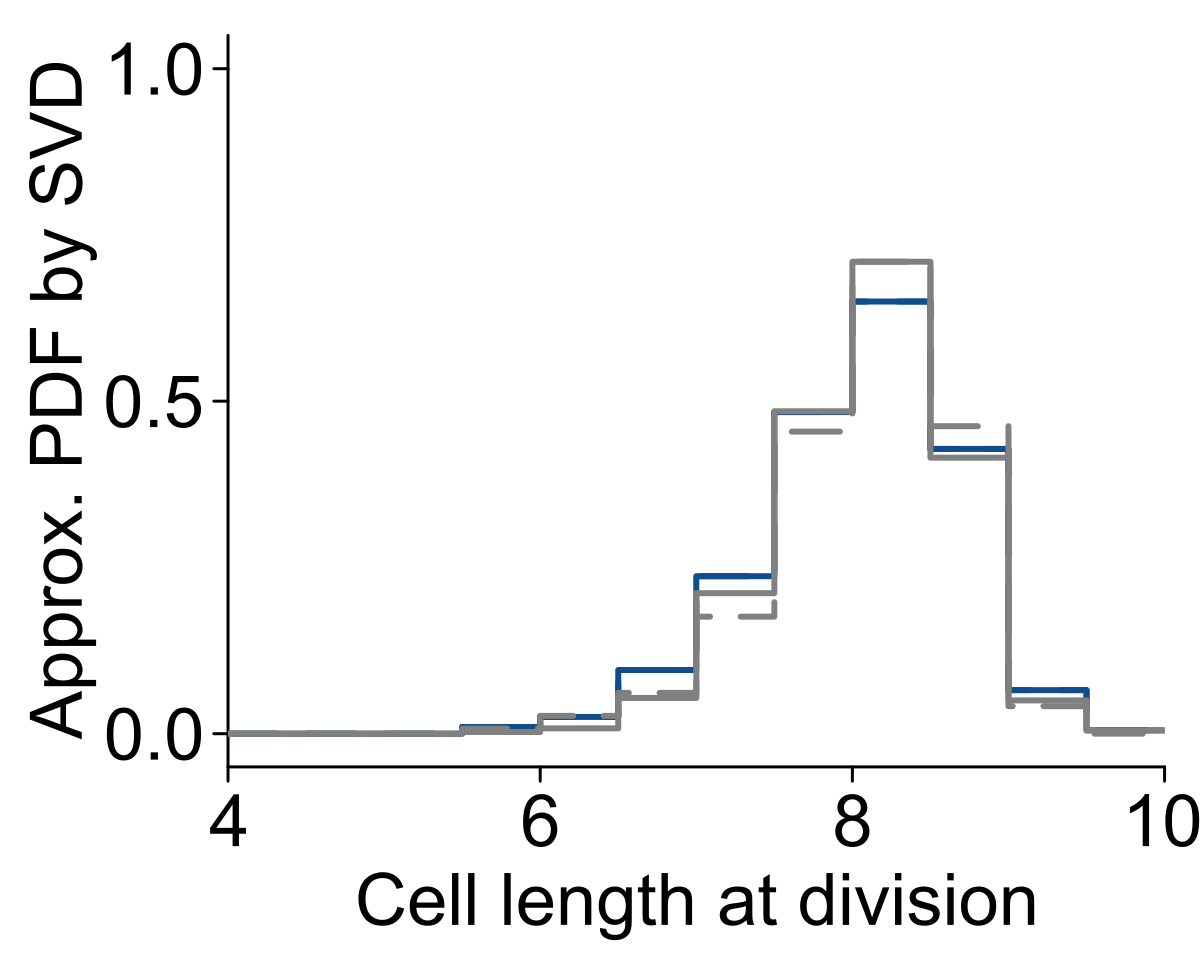

In [20]:
yU_h1_sim = svd_h1_sim.U[:,1] * sqrt(svd_h1_sim.S[1])
yV_h1_sim = svd_h1_sim.V[:,1] * sqrt(svd_h1_sim.S[1])

yU_h2_sim = svd_h2_sim.U[:,1] * sqrt(svd_h2_sim.S[1])
yV_h2_sim = svd_h2_sim.V[:,1] * sqrt(svd_h2_sim.S[1])

p_UV_sim = plot(; ylim=(-0.05,1.05), xlim=(4,10), xtick=collect(4:2:10), ytick=collect(0:0.5:1), xlabel="Cell length at division", ylabel="Approx. PDF by SVD")
plot_histogram!(p_UV_sim, hedges, abs.(yU_h1_sim); lc=:dodgerblue4)
plot_histogram!(p_UV_sim, hedges, abs.(yV_h1_sim); ls=:dash, lc=:dodgerblue4)
plot_histogram!(p_UV_sim, hedges, abs.(yU_h2_sim))
plot_histogram!(p_UV_sim, hedges, abs.(yV_h2_sim); ls=:dash)
# plot_histogram!(p_UV_sim, hedges, h1_sim_normalize, lc=:black)
p_UV_sim